# Learning Matplotlib and Seaborn - Part 2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

### Scatterplots

#### Matplot

      id        make           model  year           VClass  \
0  32204      Nissan            GT-R  2013  Subcompact Cars   
1  32205  Volkswagen              CC  2013     Compact Cars   
2  32206  Volkswagen              CC  2013     Compact Cars   
3  32207  Volkswagen      CC 4motion  2013     Compact Cars   
4  32208   Chevrolet  Malibu eAssist  2013     Midsize Cars   

               drive              trans          fuelType  cylinders  displ  \
0    All-Wheel Drive    Automatic (AM6)  Premium Gasoline          6    3.8   
1  Front-Wheel Drive  Automatic (AM-S6)  Premium Gasoline          4    2.0   
2  Front-Wheel Drive     Automatic (S6)  Premium Gasoline          6    3.6   
3    All-Wheel Drive     Automatic (S6)  Premium Gasoline          6    3.6   
4  Front-Wheel Drive     Automatic (S6)  Regular Gasoline          4    2.4   

   pv2  pv4     city    UCity  highway  UHighway     comb  co2  feScore  \
0   79    0  16.4596  20.2988  22.5568   30.1798  18.7389  471        4

Text(0, 0.5, 'Combned Fuel Eff (mpg)')

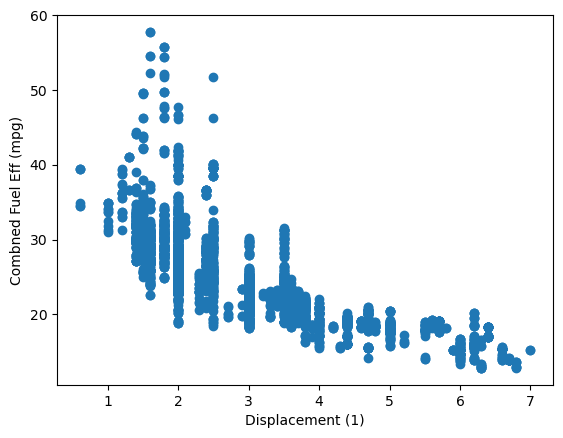

In [5]:
fuel_econ = pd.read_csv('./csvs/fuel-econ.csv')
print(fuel_econ.head())

plt.scatter(data=fuel_econ, x='displ', y='comb');

plt.xlabel('Displacement (1)')
plt.ylabel('Combned Fuel Eff (mpg)')

#### Seaborn

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

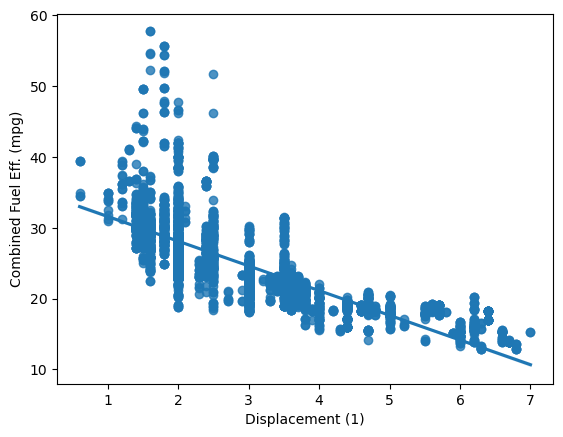

In [6]:
sb.regplot(data=fuel_econ, x='displ', y='comb');
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

Scatter plot showing a positive correlation between two variables

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

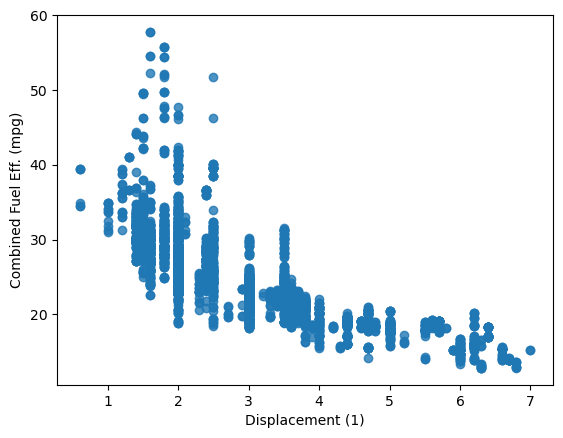

In [8]:
sb.regplot(data=fuel_econ, x='displ', y='comb', fit_reg=False);
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

Plot the regression line on the transformed data

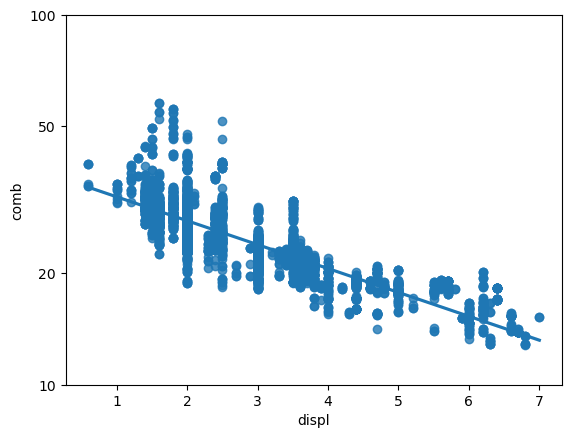

In [7]:
def log_trans(x, inverse=False):
    if not inverse:
        return np.log10(x)
    else:
        return np.power(10, x)

sb.regplot(data=fuel_econ, x=fuel_econ['displ'], y=fuel_econ['comb'].apply(log_trans))
tick_locs = [10, 20, 50, 100]
plt.yticks(log_trans(tick_locs), tick_locs);

#### Overplotting, Transparency, and Jitter

Jitter

<Axes: xlabel='year', ylabel='comb'>

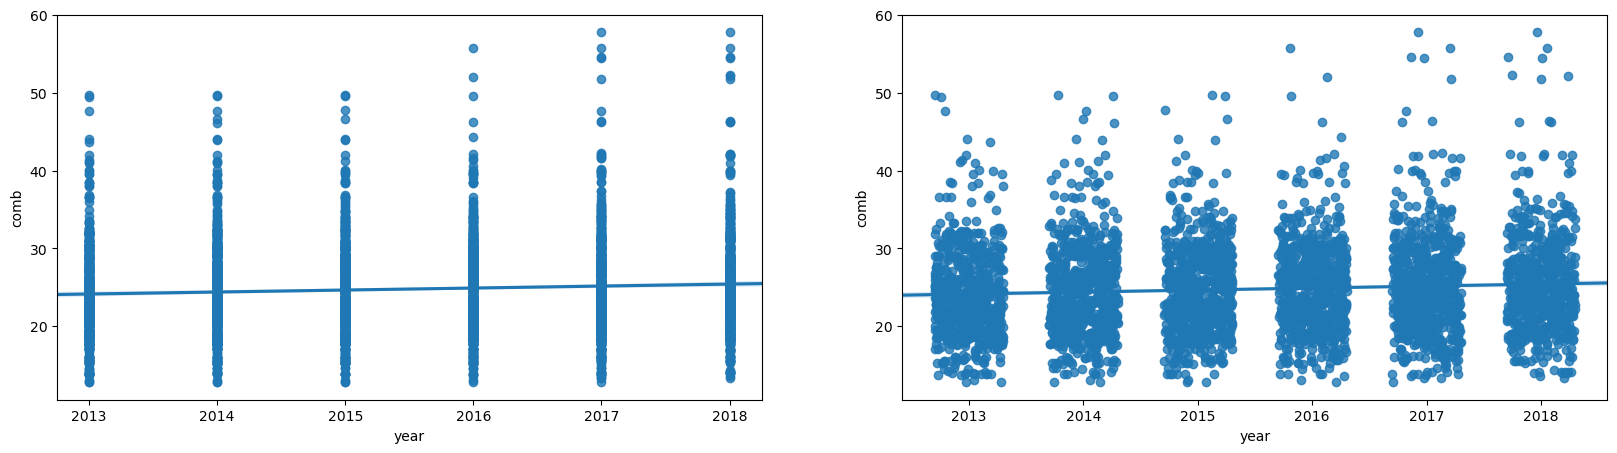

In [9]:
plt.figure(figsize = [20,5])

plt.subplot(1,2,1)
sb.regplot(data=fuel_econ, x='year', y='comb', truncate=False)

plt.subplot(1,2,2)
sb.regplot(data=fuel_econ, x='year', y='comb', truncate=False, x_jitter=0.3)

Jitter and transparency

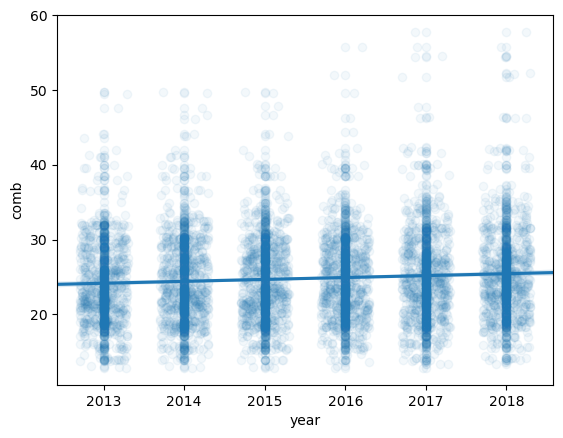

In [11]:
# plt.figure(figsize = [20,5])


# plt.subplot(1,2,1)
sb.regplot(data=fuel_econ, x='year', y='comb', truncate=False, x_jitter=0.3, scatter_kws={'alpha': 1/20})

# plt.subplot(1,2,2)
plt.scatter(data=fuel_econ, x='year', y='comb', alpha=1/20)


#### Heatmaps

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

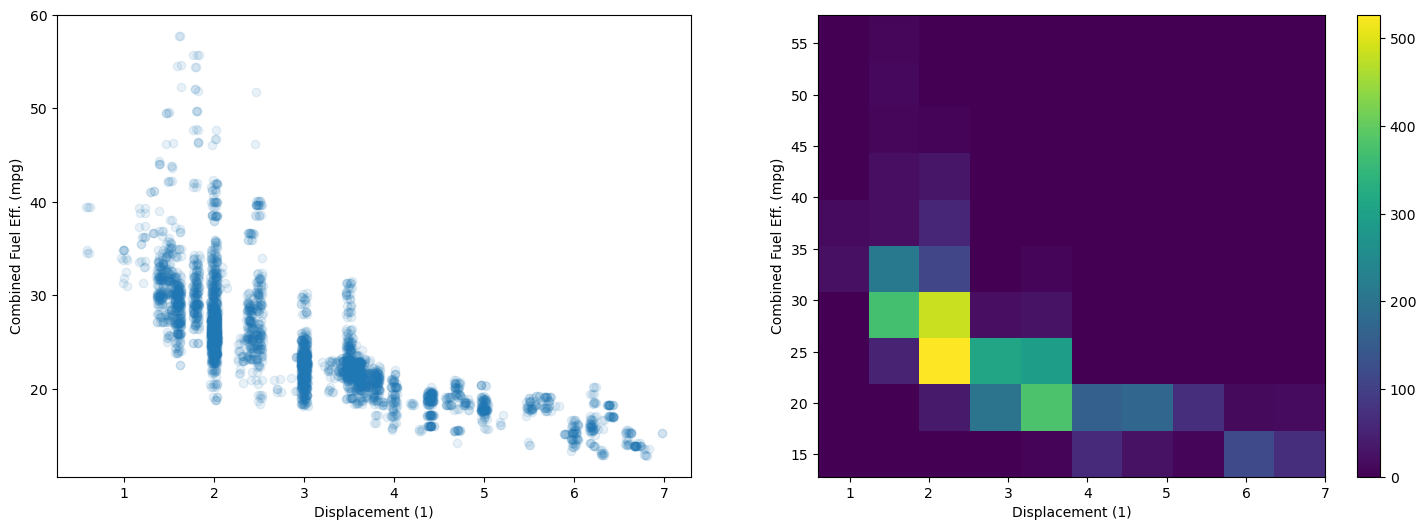

In [13]:
plt.figure(figsize=[18,6])

plt.subplot(1,2,1)
sb.regplot(data=fuel_econ, x='displ', y='comb', x_jitter=0.04, scatter_kws={'alpha': 1/10}, fit_reg=False)
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')


plt.subplot(1,2,2)
plt.hist2d(data=fuel_econ, x='displ', y='comb')
plt.colorbar()
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

#### Variations

Setting a minimun bound on counts and a reverse color map

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

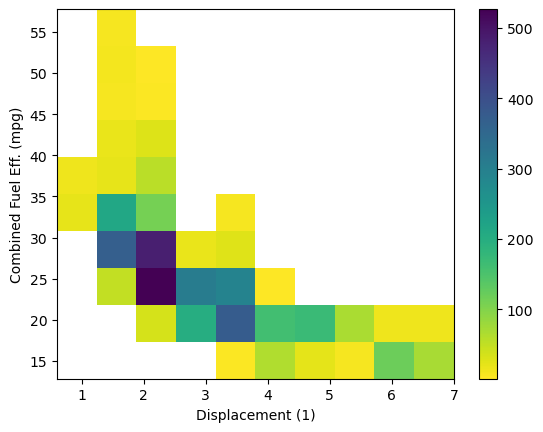

In [16]:
plt.hist2d(data=fuel_econ, x='displ', y='comb', cmin=0.5, cmap='viridis_r')
plt.colorbar()
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

Specify bin edges

Text(0, 0.5, 'Combined Fuel Eff. (mpg)')

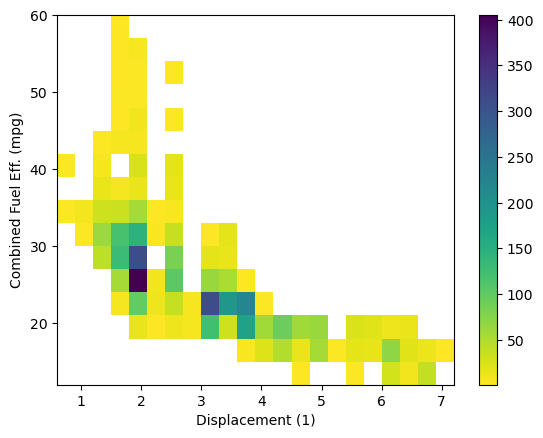

In [19]:
bins_x = np.arange(0.6, 7 + 0.3, 0.3)
bins_y = np.arange(12, 58 + 3, 3)

plt.hist2d(data=fuel_econ, x='displ', y='comb', cmin=0.5, cmap='viridis_r', bins=[bins_x,bins_y])
plt.colorbar()
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

Adding annotatio on each cell using pyplot.text() func

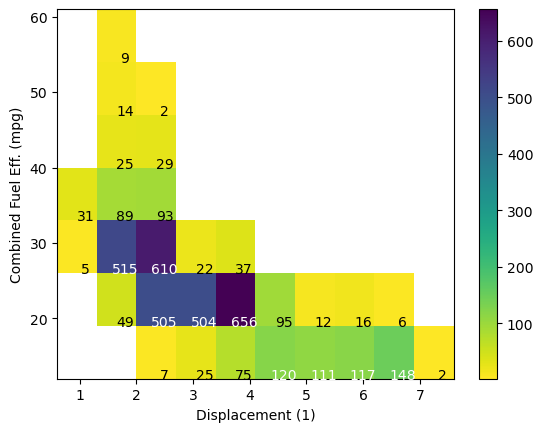

In [20]:
bins_x = np.arange(0.6, 7 + 0.7, 0.7)
bins_y = np.arange(12, 58 + 7, 7)

h2d = plt.hist2d(data=fuel_econ, x='displ', y='comb', cmin=0.5, cmap='viridis_r', bins=[bins_x, bins_y])

plt.colorbar()
plt.xlabel('Displacement (1)')
plt.ylabel('Combined Fuel Eff. (mpg)')

counts = h2d[0]

for i in range(counts.shape[0]):
    for j in range(counts.shape[1]):
        c = counts[i,j]
        if c >= 100:
            plt.text(bins_x[i] + 0.5, bins_y[j] + 0.5, int(c), ha='center', va='center', color='white')
        elif c > 0:
            plt.text(bins_x[i] + 0.5, bins_y[j] + 0.5, int(c), ha='center', va='center', color='black')